In [16]:
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
df = pd.read_excel('BCG Gen AI.xlsx', sheet_name=None)

In [4]:
for key, value in df.items():
    value['Company']=key



In [5]:
df['Microsoft'] = df['Microsoft'].rename(columns={'2025(Millions USD)': '2025', '2024(Millions USD)': '2024', '2023(Millions USD)': '2023'})
df['Microsoft']

,Financial Category,2025,2024,2023,Company
0,Total Revenue,281724,245122,211915,Microsoft
1,Net Income,101832,88136,72361,Microsoft
2,Total Assets,619003,512163,411976,Microsoft
3,Total Liabilities,275524,243686,205753,Microsoft
4,Cash Flow,136162,118548,87582,Microsoft


Merged individual sheels into a single dataframe

In [6]:
df_merge=pd.concat([df['Microsoft'], df['Tesla'], df['Apple']], axis=0, ignore_index=True)
df_merge

,Financial Category,2025,2024,2023,Company
0,Total Revenue,281724,245122,211915,Microsoft
1,Net Income,101832,88136,72361,Microsoft
2,Total Assets,619003,512163,411976,Microsoft
3,Total Liabilities,275524,243686,205753,Microsoft
4,Cash Flow,136162,118548,87582,Microsoft
5,Total Revenue,94827,97690,96773,Tesla
6,Net Income,3855,7153,14974,Tesla
7,Total Assets,137806,122070,106618,Tesla
8,Total Liabilities,54941,48390,43009,Tesla
9,Cash Flow,14747,14923,13256,Tesla


Melt the year columns and then Pivoted the data for yearwise analysis

In [7]:
# 1. Melt the 2025, 2024, and 2023 columns into a single 'Year' column
df_melted = df_merge.melt(
    id_vars=['Company', 'Financial Category'], 
    value_vars=['2025', '2024', '2023'], 
    var_name='Year', 
    value_name='Amount'
)

# 2. Pivot the table to make the financial metrics your new columns
df_final = df_melted.pivot(
    index=['Company', 'Year'], 
    columns='Financial Category', 
    values='Amount'
).reset_index()

df_final
         

Financial Category,Company,Year,Cash Flow,Net Income,Total Assets,Total Liabilities,Total Revenue
0,Apple,2023,110543,96995,352583,290437,383285
1,Apple,2024,118254,93736,364980,308030,391035
2,Apple,2025,111482,112010,359241,285508,416161
3,Microsoft,2023,87582,72361,411976,205753,211915
4,Microsoft,2024,118548,88136,512163,243686,245122
5,Microsoft,2025,136162,101832,619003,275524,281724
6,Tesla,2023,13256,14974,106618,43009,96773
7,Tesla,2024,14923,7153,122070,48390,97690
8,Tesla,2025,14747,3855,137806,54941,94827


Calculated yearwise change in the metrics.

Observed Microsoft showed the largest pct increase from last year in Total Revenue in the year 2024 along with highest increase in pct change in all metrics for all companies over all 2023-2025

Apple showed increasing pct revenue growth over 2023-2025, Apple and Microsoft both had positive revenue growth but Tesla showed negative revenue growth in the period 2025.

Microsoft had highest net income growth in 2024 where as Apple had the highest in 2025.

MS and Tesla both had positive Total assests pct increase  over 2023-2025 but Apple had a decrease in total assest 2025 from 2024.

Only MS had postive pct increase in Cashflow for both years over 2023-2025

MS and Tesla both showed increasing trend in total liablitites.

Overall Conclusion:
Over the three year period MS had shown most promising growth followed by Apple is showing steady trends and Tesla seems negative trends despite increase in total assets.


In [27]:
df_final['Revenue Growth (%)'] = df_final.groupby(['Company'])['Total Revenue'].pct_change() * 100
df_final['Net Income Growth (%)'] = df_final.groupby(['Company'])['Net Income'].pct_change() * 100
df_final['Total Assets (%)'] = df_final.groupby(['Company'])['Total Assets'].pct_change() * 100
df_final['Cash Flow (%)'] = df_final.groupby(['Company'])['Cash Flow'].pct_change() * 100
df_final['Total Liabilities (%)'] = df_final.groupby(['Company'])['Total Liabilities'].pct_change() * 100

df_final

Financial Category,Company,Year,Cash Flow,Net Income,Total Assets,Total Liabilities,Total Revenue,Revenue Growth (%),Net Income Growth (%),Total Assets (%),Cash Flow (%),Total Liabilities (%),Cash Flow (%)
0,Apple,2023,110543,96995,352583,290437,383285,NaN,NaN,NaN,NaN,NaN,NaN
1,Apple,2024,118254,93736,364980,308030,391035,2.021994,-3.359967,3.516052,6.975566,6.057424,6.975566
2,Apple,2025,111482,112010,359241,285508,416161,6.425512,19.495178,-1.572415,-5.726656,-7.311625,-5.726656
3,Microsoft,2023,87582,72361,411976,205753,211915,NaN,NaN,NaN,NaN,NaN,NaN
4,Microsoft,2024,118548,88136,512163,243686,245122,15.669962,21.800417,24.318650,35.356580,18.436183,35.356580
5,Microsoft,2025,136162,101832,619003,275524,281724,14.932156,15.539621,20.860546,14.858117,13.065174,14.858117
6,Tesla,2023,13256,14974,106618,43009,96773,NaN,NaN,NaN,NaN,NaN,NaN
7,Tesla,2024,14923,7153,122070,48390,97690,0.947578,-52.230533,14.492862,12.575438,12.511335,12.575438
8,Tesla,2025,14747,3855,137806,54941,94827,-2.930699,-46.106529,12.890964,-1.179388,13.537921,-1.179388


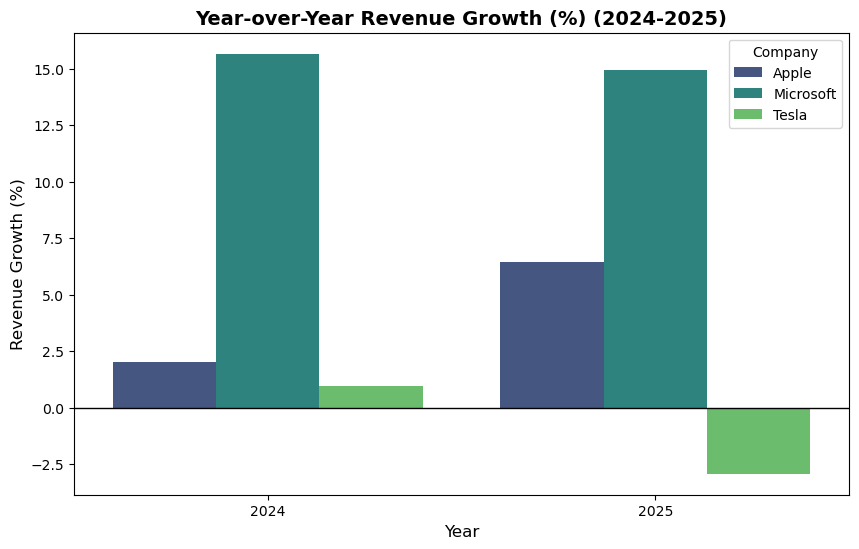

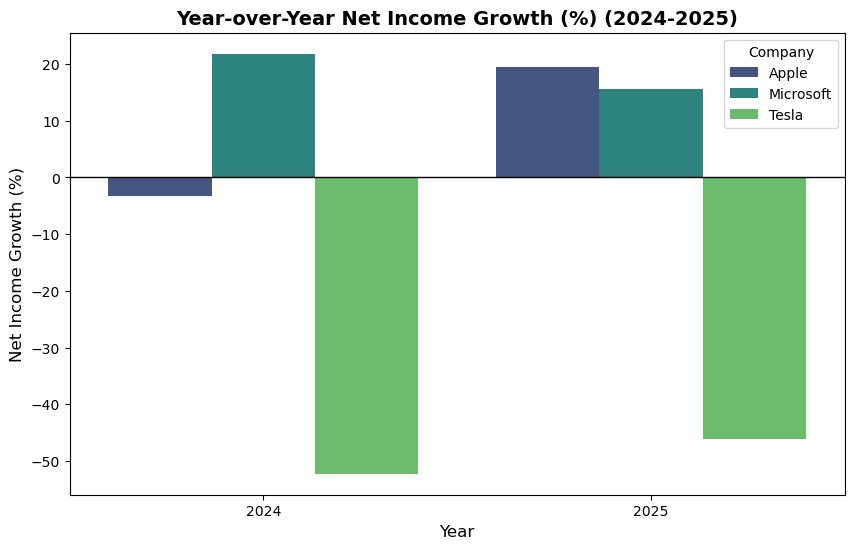

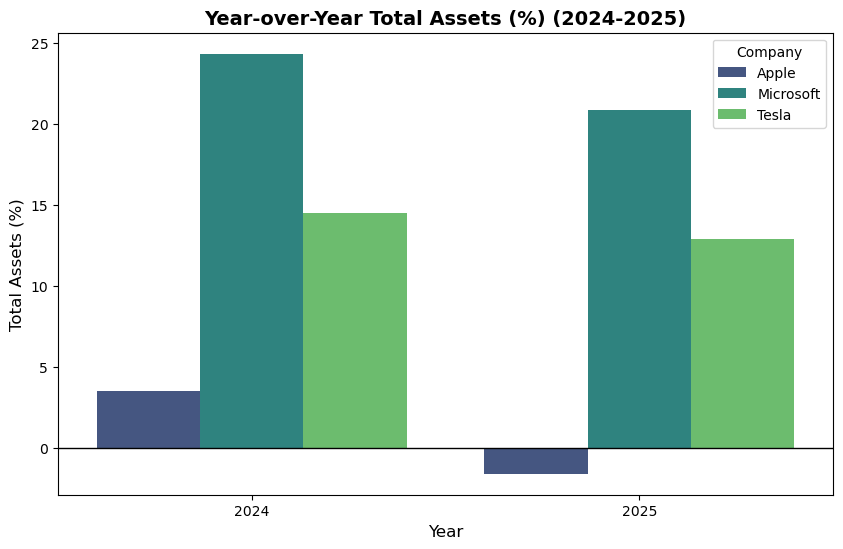

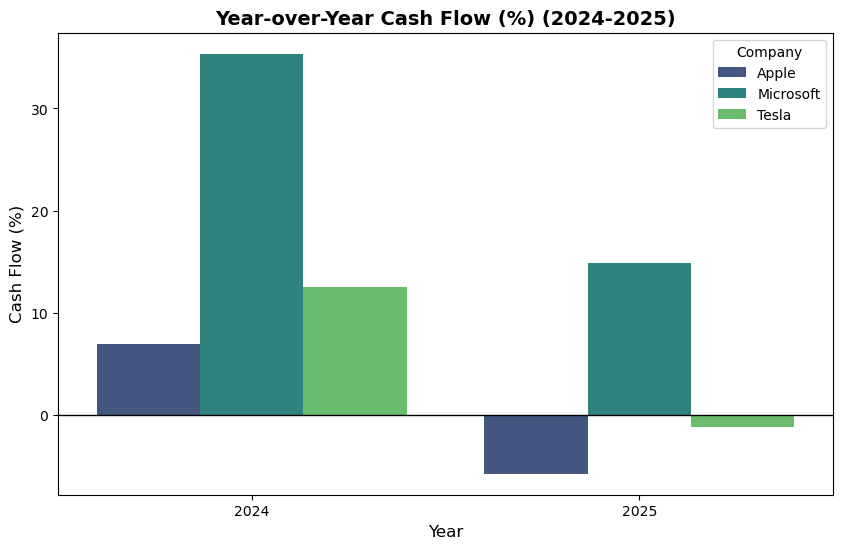

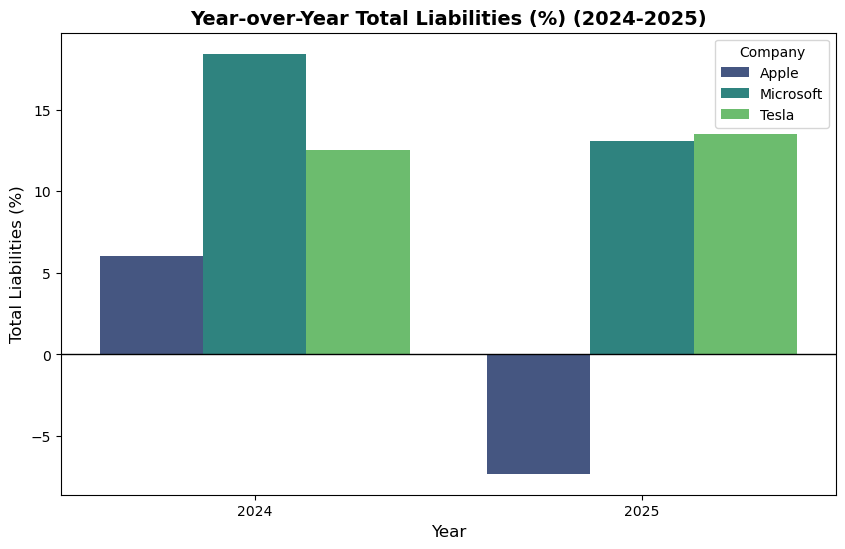

In [30]:
def plot_financial_metric(metric_name):
    # 1. Filter out the 2023 baseline year
    df_plot = df_final.dropna(subset=[metric_name])
    
    # 2. Set up the figure size
    plt.figure(figsize=(10, 6))
    
    # 3. Create the grouped bar chart  
    sns.barplot(data=df_plot, x='Year', y=metric_name, hue='Company', palette='viridis')
    
    # 4. Add titles, labels, and a baseline at 0%
    plt.title('Year-over-Year {} (2024-2025)'.format(metric_name), fontsize=14, fontweight='bold')
    plt.xlabel('Year', fontsize=12)
    plt.ylabel(metric_name, fontsize=12)
    plt.axhline(0, color='black', linewidth=1) # Adds a solid line at 0% for visual reference
    plt.legend(title='Company')
    
    # 5. Display the plot
    plt.show()

# List of all the metric columns you calculated
metrics_to_plot = [
    'Revenue Growth (%)', 
    'Net Income Growth (%)', 
    'Total Assets (%)', 
    'Cash Flow (%)', 
    'Total Liabilities (%)'
]

# Generate all 5 charts instantly
for metric in metrics_to_plot:
    plot_financial_metric(metric)
